In [2]:
# Libraries are loaded in the next cell; keep one setup block.


In [3]:
pkgs <- c("caret", "readr", "corrplot", "ggplot2", "dplyr", 
          "BayesTree", "gridExtra", "reshape2", "car")

invisible(lapply(pkgs, function(pkg) {
  suppressMessages(
    suppressWarnings(
      suppressPackageStartupMessages(
        library(pkg, character.only = TRUE)
      )
    )
  )
}))

## 1. EDA

In [5]:
myData <- read.csv("online_shoppers_intention.csv")

### Features

In [6]:
## 1.  Administrative : # of pages of this type (administrative) that the user visited.
## 2.  Administrative_Duration : the amount of time spent in this category of pages
## 3.  Informational : # of pages of this type (informational) that the user visited.
## 4.  Informational_Duration : the amount of time spent in this category of pages.
## 5.  ProductRelated : # of pages of this type (product related) that the user visited.
## 6.  ProductRelated_Duration : the amount of time spent in this category of pages.
## 7.  BounceRates : The percentage of visitors who enter the website through that page and exit without triggering any additional tasks.
## 8.  ExitRates : The average value of the page averaged over the value of the target page and/or the completion of an eCommerce
## 9.  PageValues : The average value of the pages visited by the user. This metric is often used as an indicator of how valuable a page is in terms of generating revenue.
## 10. SpecialDay : the closeness of the site visiting time to a specific special day (e.g., Mother’s Day, Valentine's Day) in which the sessions are more likely to be finalized with a transaction

## 11. Month
## 12. OperatingSystems
## 13. Browser : The browser used by the user.
## 14. Region : The region from which the user is accessing the website.
## 15. TrafficType : The type of traffic (e.g., direct, paid search, organic search, referral).
## 16. VisitorType : A categorization of users (e.g., Returning Visitor, New Visitor).
## 17. Weekend : A boolean indicating whether the session occurred on a weekend.

## 18. Revenue : A binary variable indicating whether the session ended in a transaction (purchase).

### 1) Data Check

In [7]:
head(myData)

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
,<int>,<dbl>,<int>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<int>,<int>,<int>,<int>,<chr>,<lgl>,<lgl>
1,0,0,0,0,1,0.000000,0.20000000,0.2000000,0,0,Feb,1,1,1,1,Returning_Visitor,FALSE,FALSE
2,0,0,0,0,2,64.000000,0.00000000,0.1000000,0,0,Feb,2,2,1,2,Returning_Visitor,FALSE,FALSE
3,0,0,0,0,1,0.000000,0.20000000,0.2000000,0,0,Feb,4,1,9,3,Returning_Visitor,FALSE,FALSE
4,0,0,0,0,2,2.666667,0.05000000,0.1400000,0,0,Feb,3,2,2,4,Returning_Visitor,FALSE,FALSE
5,0,0,0,0,10,627.500000,0.02000000,0.0500000,0,0,Feb,3,3,1,4,Returning_Visitor,TRUE,FALSE
6,0,0,0,0,19,154.216667,0.01578947,0.0245614,0,0,Feb,2,2,1,3,Returning_Visitor,FALSE,FALSE


In [8]:
dim(myData)

[1] 12330    18

In [9]:
summary(myData)

 Administrative   Administrative_Duration Informational    
 Min.   : 0.000   Min.   :   0.00         Min.   : 0.0000  
 1st Qu.: 0.000   1st Qu.:   0.00         1st Qu.: 0.0000  
 Median : 1.000   Median :   7.50         Median : 0.0000  
 Mean   : 2.315   Mean   :  80.82         Mean   : 0.5036  
 3rd Qu.: 4.000   3rd Qu.:  93.26         3rd Qu.: 0.0000  
 Max.   :27.000   Max.   :3398.75         Max.   :24.0000  
 Informational_Duration ProductRelated   ProductRelated_Duration
 Min.   :   0.00        Min.   :  0.00   Min.   :    0.0        
 1st Qu.:   0.00        1st Qu.:  7.00   1st Qu.:  184.1        
 Median :   0.00        Median : 18.00   Median :  598.9        
 Mean   :  34.47        Mean   : 31.73   Mean   : 1194.8        
 3rd Qu.:   0.00        3rd Qu.: 38.00   3rd Qu.: 1464.2        
 Max.   :2549.38        Max.   :705.00   Max.   :63973.5        
  BounceRates         ExitRates         PageValues        SpecialDay     
 Min.   :0.000000   Min.   :0.00000   Min.   :  0.0

In [10]:
table(myData$Revenue)


FALSE  TRUE 
10422  1908 

In [11]:
# Do not set a classification threshold using the full dataset.
# The models below use a prespecified 0.5 cutoff.


In [12]:
str(myData)

'data.frame':	12330 obs. of  18 variables:
 $ Administrative         : int  0 0 0 0 0 0 0 1 0 0 ...
 $ Administrative_Duration: num  0 0 0 0 0 0 0 0 0 0 ...
 $ Informational          : int  0 0 0 0 0 0 0 0 0 0 ...
 $ Informational_Duration : num  0 0 0 0 0 0 0 0 0 0 ...
 $ ProductRelated         : int  1 2 1 2 10 19 1 0 2 3 ...
 $ ProductRelated_Duration: num  0 64 0 2.67 627.5 ...
 $ BounceRates            : num  0.2 0 0.2 0.05 0.02 ...
 $ ExitRates              : num  0.2 0.1 0.2 0.14 0.05 ...
 $ PageValues             : num  0 0 0 0 0 0 0 0 0 0 ...
 $ SpecialDay             : num  0 0 0 0 0 0 0.4 0 0.8 0.4 ...
 $ Month                  : chr  "Feb" "Feb" "Feb" "Feb" ...
 $ OperatingSystems       : int  1 2 4 3 3 2 2 1 2 2 ...
 $ Browser                : int  1 2 1 2 3 2 4 2 2 4 ...
 $ Region                 : int  1 1 9 2 1 1 3 1 2 1 ...
 $ TrafficType            : int  1 2 3 4 4 3 3 5 3 2 ...
 $ VisitorType            : chr  "Returning_Visitor" "Returning_Visitor" "Returning_Visito

### 2) Data Preprocessing 

In [13]:
myData$Month <- as.factor(myData$Month)
myData$OperatingSystems <- as.factor(myData$OperatingSystems)
myData$Browser <- as.factor(myData$Browser)
myData$Region <- as.factor(myData$Region)
myData$TrafficType <- as.factor(myData$TrafficType)

### 3) Unique Value Analysis(categorical features)

In [14]:
unique(myData$Month)
unique(myData$OperatingSystems)
unique(myData$Browser)
unique(myData$Region)
unique(myData$TrafficType)
unique(myData$VisitorType)
unique(myData$Weekend)
unique(myData$Revenue)

[1] Feb  Mar  May  Oct  June Jul  Aug  Nov  Sep  Dec 
Levels: Aug Dec Feb Jul June Mar May Nov Oct Sep

[1] 1 2 4 3 7 6 8 5
Levels: 1 2 3 4 5 6 7 8

[1] 1  2  3  4  5  6  7  10 8  9  12 13 11
Levels: 1 2 3 4 5 6 7 8 9 10 11 12 13

[1] 1 9 2 3 4 5 6 7 8
Levels: 1 2 3 4 5 6 7 8 9

[1] 1  2  3  4  5  6  7  8  9  10 11 12 13 14 15 18 19 16 17 20
Levels: 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19 20

[1] "Returning_Visitor" "New_Visitor"       "Other"

[1] FALSE  TRUE

[1] FALSE  TRUE

In [15]:
# Rename "June" to "Jun"

In [16]:
levels(myData$Month)[levels(myData$Month)=="June"] <- "Jun"
unique(myData$Month)

[1] Feb Mar May Oct Jun Jul Aug Nov Sep Dec
Levels: Aug Dec Feb Jul Jun Mar May Nov Oct Sep

### 4) Missing value analysis

In [17]:
sum(is.na(myData))

[1] 0

### 5) Correlation Analysis

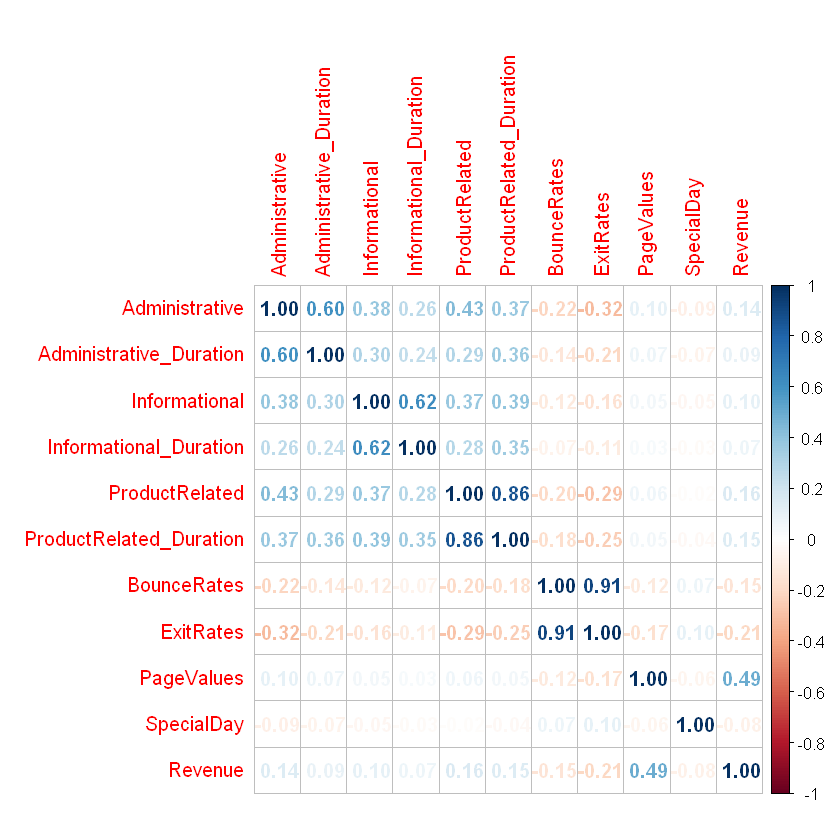

In [18]:
numeric_list = c('Administrative', 'Administrative_Duration','Informational','Informational_Duration','ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Revenue')
c <- round(cor(myData[,numeric_list]), 2)
corrplot(c, method = "number")

### 6) Weekend and Revenue Analysis

In [19]:
table(myData$Weekend, myData$Revenue)

       
        FALSE TRUE
  FALSE  8053 1409
  TRUE   2369  499

In [20]:
#Perform the Chi-Square Test
chisq.test(myData$Weekend, myData$Revenue, correct = FALSE)


	Pearson's Chi-squared test

data:  myData$Weekend and myData$Revenue
X-squared = 10.582, df = 1, p-value = 0.001142


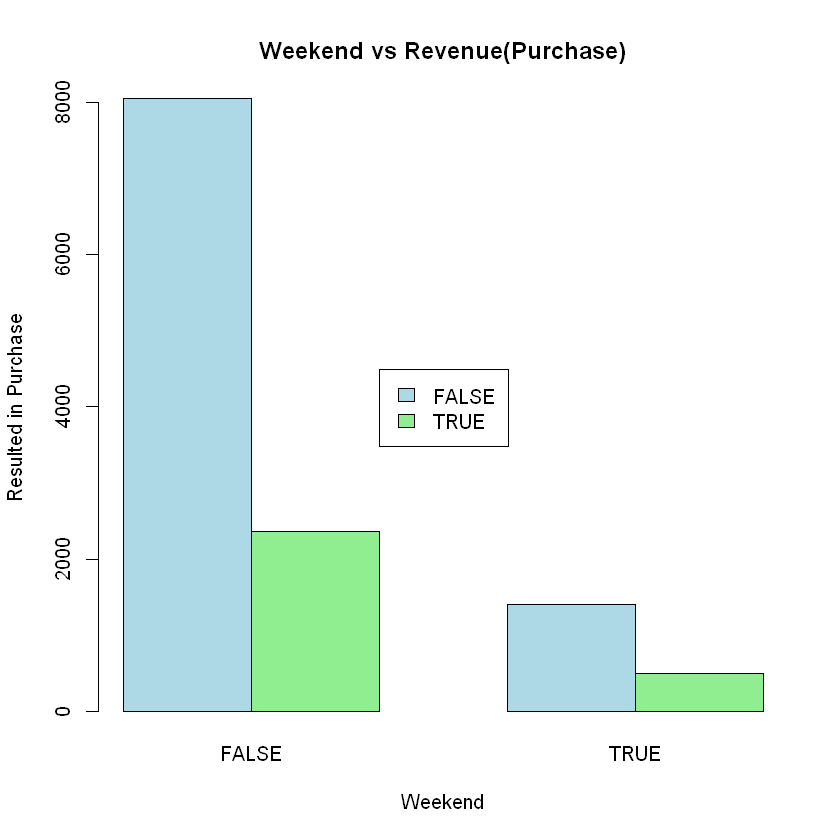

In [21]:
Weekend_R <- table(myData$Weekend, myData$Revenue)
barplot(Weekend_R, beside = TRUE, col = c("lightblue", "lightgreen"),
        main = "Weekend vs Revenue(Purchase)",
        xlab = "Weekend", ylab = "Resulted in Purchase")

legend("center", legend = rownames(Weekend_R), fill = c("lightblue", "lightgreen"))

### 7) Page type and Revenue Analysis

In [22]:
page_cnt_df <- myData %>%
    group_by(Revenue) %>%
    summarise(
        Administrative = mean(Administrative),
        Informational = mean(Informational),
        ProductRelated = mean(ProductRelated)
        )

In [23]:
page_cnt_df <- page_cnt_df %>%
  mutate(Revenue = ifelse(Revenue == TRUE, 'Buyers', 'Non-Buyers'))

In [24]:
page_cnt_df

Revenue,Administrative,Informational,ProductRelated
<chr>,<dbl>,<dbl>,<dbl>
Non-Buyers,2.117732,0.4518327,28.71464
Buyers,3.393606,0.7861635,48.21017


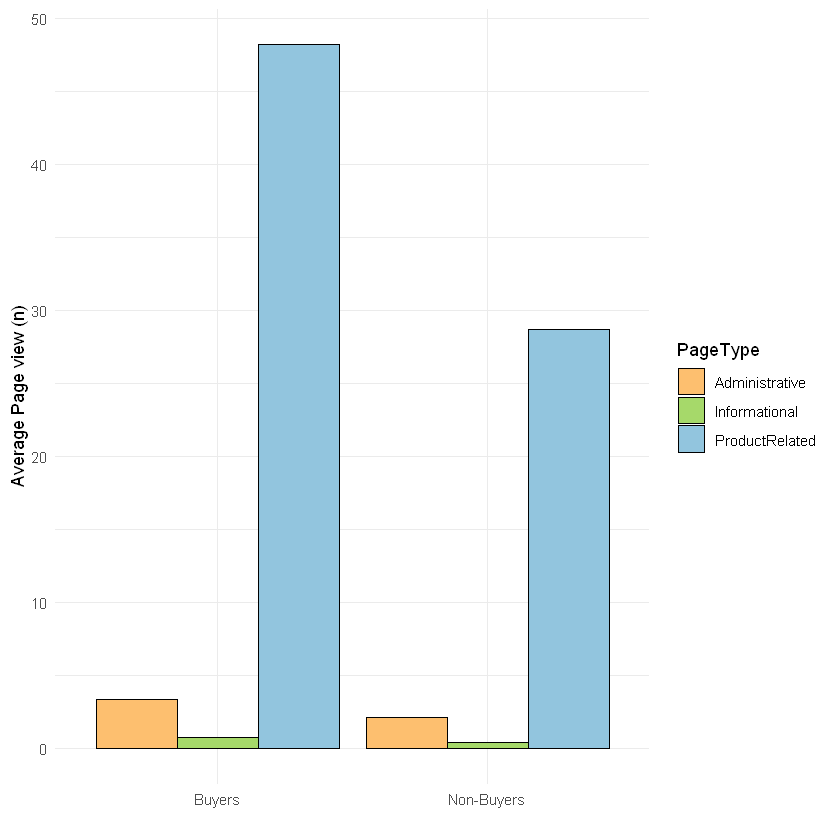

In [25]:
melted_df <- melt(page_cnt_df, id.vars = 'Revenue', measure.vars = c('Administrative', 'Informational', 'ProductRelated'),
                  variable.name = 'PageType', value.name = 'Value')
page_colors <- c('ProductRelated' = '#92c5de', 'Administrative' = '#fdbf6f', 'Informational' = '#a6d96a')
# Plotting
ggplot(melted_df, aes(x = Revenue, y = Value, fill = PageType)) +
  geom_bar(stat = 'identity', position = 'dodge', color = 'black') +
  labs(x = '', y = 'Average Page view (n)') +
  scale_fill_manual(values = page_colors) +
  theme_minimal()

### 8) Visitor Type and Revenue Analysis

In [26]:
visitor_df <- myData %>%
    group_by(VisitorType, Revenue) %>%
    summarise(
        cnt = n()
        )
options(dplyr.summarise.inform = FALSE)

`summarise()` has grouped output by 'VisitorType'. You can override using the `.groups` argument.


In [27]:
visitor_df <- visitor_df %>%
  mutate(Revenue = ifelse(Revenue == TRUE, 'Buyers', 'Non-Buyers'))

In [28]:
visitor_df

VisitorType,Revenue,cnt
<chr>,<chr>,<int>
New_Visitor,Non-Buyers,1272
New_Visitor,Buyers,422
Other,Non-Buyers,69
Other,Buyers,16
Returning_Visitor,Non-Buyers,9081
Returning_Visitor,Buyers,1470


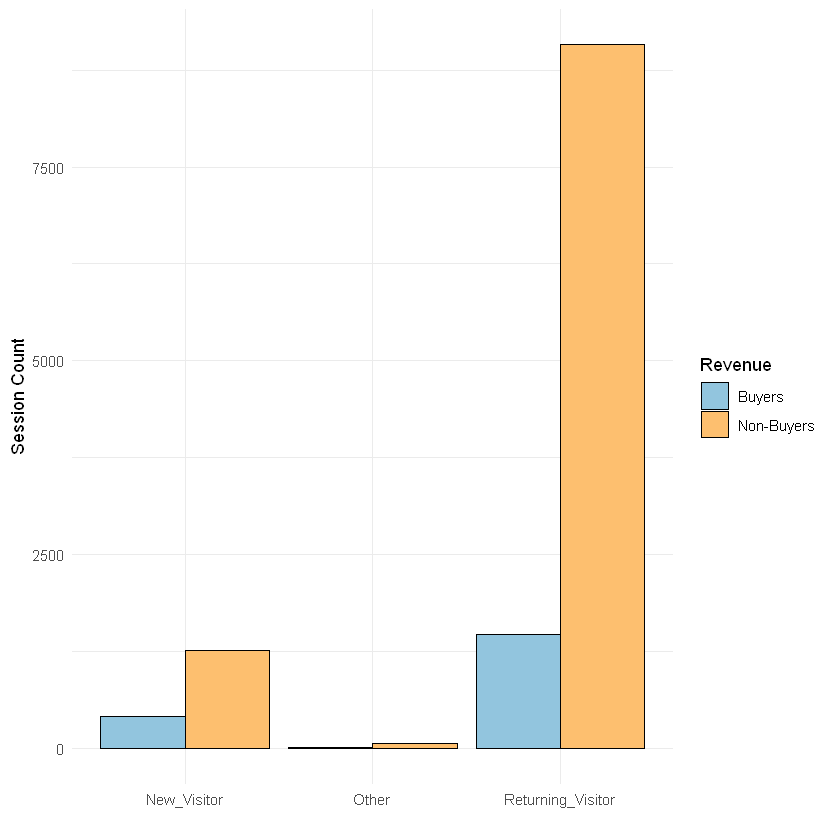

In [29]:
page_colors <- c('Buyers' = '#92c5de', 'Non-Buyers' = '#fdbf6f')

# Plotting
ggplot(visitor_df, aes(x = VisitorType, y = cnt, fill = Revenue)) +
  geom_bar(stat = 'identity', position = 'dodge', color = 'black') +
  labs(x = '', y = 'Session Count') +
  scale_fill_manual(values = page_colors) +
  theme_minimal()

### 9) Engagement Metrics and Revenue Analysis

`geom_smooth()` using formula = 'y ~ x'


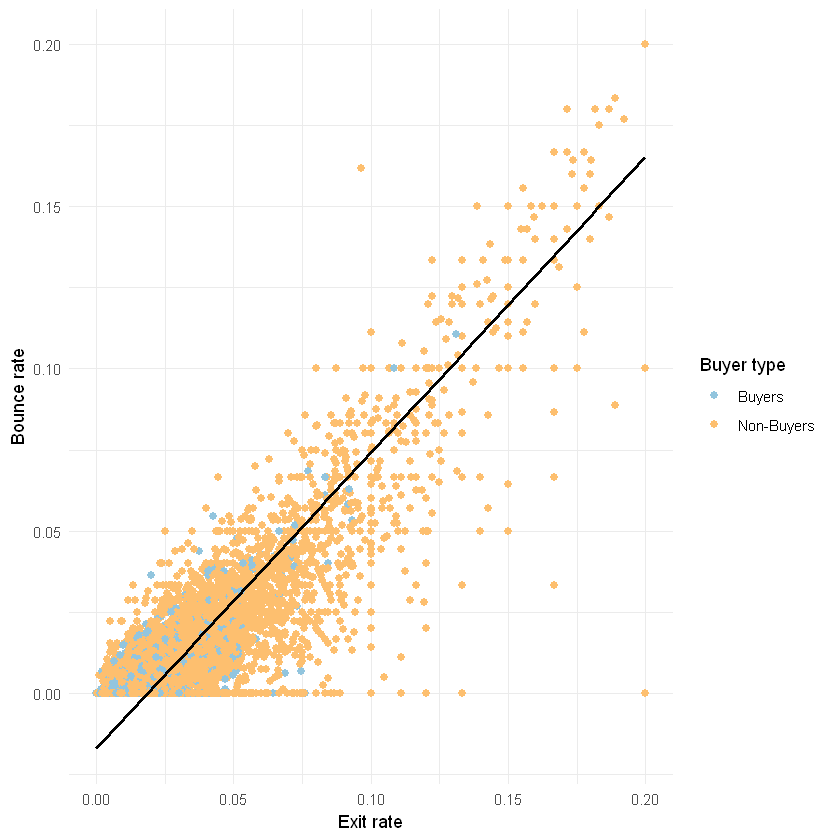

In [30]:
# Create a copy of the dataframe
df_bounce_exit <- myData

# Map True to 'Buyers' and False to 'Non-Buyers' in the 'Revenue' column
df_bounce_exit$Revenue <- ifelse(df_bounce_exit$Revenue, 'Buyers', 'Non-Buyers')

# Define custom colors
custom_colors <- c('Buyers' = '#92c5de', 'Non-Buyers' = '#fdbf6f')

# Scatterplot with custom colors
ggplot(df_bounce_exit, aes(x = ExitRates, y = BounceRates, color = Revenue)) +
  geom_point(size = 2) +
  scale_color_manual(values = custom_colors) +
  
  # Add regression line
  geom_smooth(method = 'lm', se = FALSE, color = 'black') +
  
  labs(x = 'Exit rate', y = 'Bounce rate', color = 'Buyer type') +
  theme_minimal()

### 10) Month and Revenue Analysis

In [31]:
# Filter data for buyers
buyers <- myData[myData$Revenue == TRUE, ]
# Group by Month and count buyers
buyers_count <- buyers %>%
  group_by(Month) %>%
  summarise(Buyers = n())

In [32]:
buyers_count

Month,Buyers
<fct>,<int>
Aug,76
Dec,216
Feb,3
Jul,66
Jun,29
Mar,192
May,365
Nov,760
Oct,115


In [33]:
# Define the correct order of month names
month_order <- c("Feb", "Mar", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec")
buyers_count$Month <- factor(buyers_count$Month, levels = month_order)
buyers_count <- buyers_count[order(buyers_count$Month), , drop = FALSE]

In [34]:
buyers_count

Month,Buyers
<fct>,<int>
Feb,3
Mar,192
May,365
Jun,29
Jul,66
Aug,76
Sep,86
Oct,115
Nov,760


In [35]:
# Filter and count non-buyers by month
non_buyers <- myData[myData$Revenue == FALSE, ]
non_buyers_count <- non_buyers %>%
  group_by(Month) %>%
  summarise(Non_Buyers = n(), .groups = 'drop')
non_buyers_count$Month <- factor(as.character(non_buyers_count$Month), levels = month_order)
non_buyers_count <- non_buyers_count[order(non_buyers_count$Month), , drop = FALSE]


In [36]:
non_buyers_count

Month,Non_Buyers
<fct>,<int>
Feb,181
Mar,1715
May,2999
Jun,259
Jul,366
Aug,357
Sep,362
Oct,434
Nov,2238


In [37]:
# Merge the counts of buyers and non-buyers by month
month_customer <- merge(buyers_count, non_buyers_count, by = "Month", all = TRUE)

# Reshape data to long format
month_customer_long <- melt(month_customer, id.vars = "Month", variable.name = "Type", value.name = "SessionCount")

month_customer_long$Month <- factor(month_customer_long$Month, levels = month_order)
month_customer_long <- month_customer_long[order(month_customer_long$Month), , drop = FALSE]
rownames(month_customer_long) <- NULL

In [38]:
month_customer_long

Month,Type,SessionCount
<fct>,<fct>,<int>
Feb,Buyers,3
Feb,Non_Buyers,181
Mar,Buyers,192
Mar,Non_Buyers,1715
May,Buyers,365
May,Non_Buyers,2999
Jun,Buyers,29
Jun,Non_Buyers,259
Jul,Buyers,66


Warning message:
"Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead."


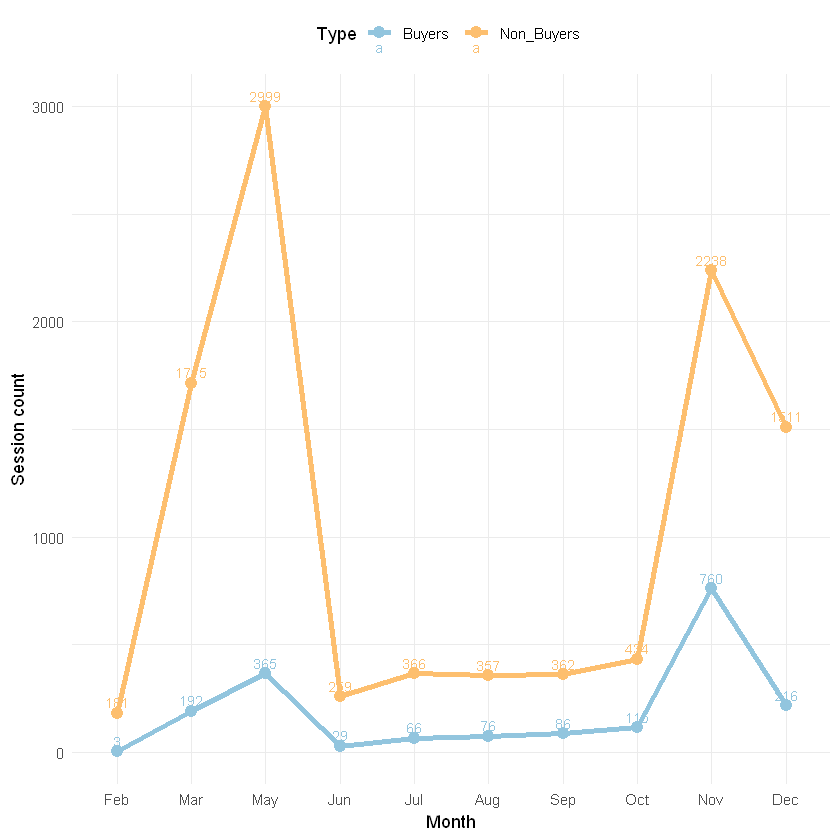

In [39]:
# Plotting
ggplot(month_customer_long, aes(x = Month, y = SessionCount, color = Type, group = Type)) +
  geom_line(size = 1.5, linetype = "solid") +
  geom_point(size = 3) +  # Removed shape aesthetic
  geom_text(aes(label = SessionCount), vjust = -0.5, hjust = 0.5, size = 3) +
  scale_color_manual(values = c("Buyers" = "#92c5de", "Non_Buyers" = "#fdbf6f"), name = "Type") +
  labs(x = "Month", y = "Session count") +
  theme_minimal() +
  theme(legend.position = "top")

## 2. Purchase prediction: corrected comparison

**Revisited evaluation.** This section updates the original undergraduate analysis: BART and logistic regression use the same stratified train/test split, preprocessing is learned only from training data, and the positive class is purchase (`Revenue = 1`). Both models use a prespecified 0.5 probability threshold. The test set is evaluated once; do not tune parameters or thresholds against it.

**Data requirement:** Place `online_shoppers_intention.csv` in the notebook's working directory. The dataset is not bundled in this repository; see the README for its source.


In [40]:
# Shared, reproducible 70/30 train/test split, stratified by Revenue.
set.seed(2026)
myData$Revenue <- as.integer(as.character(myData$Revenue) == "TRUE")
train_index <- caret::createDataPartition(factor(myData$Revenue), p = 0.70, list = FALSE)
train_raw <- myData[train_index, , drop = FALSE]
test_raw  <- myData[-train_index, , drop = FALSE]
stopifnot(nrow(train_raw) + nrow(test_raw) == nrow(myData))
stopifnot(all(train_raw$Revenue %in% c(0L, 1L)))

# Fit a dummy-variable encoding on training predictors only.
# Revenue is deliberately excluded so it cannot leak into X.
feature_names <- setdiff(names(train_raw), "Revenue")
dummy_encoder <- caret::dummyVars(~ ., data = train_raw[, feature_names, drop = FALSE], fullRank = TRUE)
x_train <- as.matrix(predict(dummy_encoder, newdata = train_raw[, feature_names, drop = FALSE]))
x_test <- as.matrix(predict(dummy_encoder, newdata = test_raw[, feature_names, drop = FALSE]))
y_train <- train_raw$Revenue
y_test <- test_raw$Revenue
stopifnot(nrow(x_train) == length(y_train), nrow(x_test) == length(y_test))
stopifnot(identical(colnames(x_train), colnames(x_test)))

cat("Train:", length(y_train), "Test:", length(y_test), "\n")
print(table(train = y_train))
print(table(test = y_test))


Train: 8632 Test: 3698 
train
   0    1 
7296 1336 
test
   0    1 
3126  572 


### 2.1 BART (probit classification)

For binary `Revenue`, `BayesTree::bart` returns posterior draws on the latent **probit** scale. Apply `pnorm()` to each posterior draw and then average across draws to estimate the posterior predictive purchase probability. Taking `pnorm(mean(latent_draws))` is **not** equivalent to averaging the transformed draws.


In [41]:
set.seed(2026)
bart_fit <- BayesTree::bart(
  x.train = x_train,
  y.train = y_train,
  x.test = x_test,
  ntree = 75,
  verbose = FALSE
)

# Rows = posterior draws; columns = test observations.
posterior_probability_draws <- pnorm(bart_fit$yhat.test)
stopifnot(ncol(posterior_probability_draws) == length(y_test))
bart_probability <- colMeans(posterior_probability_draws)

# Optional posterior 95% credible intervals for each individual's predicted probability.
bart_prob_interval <- apply(posterior_probability_draws, 2, quantile,
                            probs = c(0.025, 0.975))
bart_class <- as.integer(bart_probability >= 0.5)
head(data.frame(actual = y_test, prob = bart_probability,
                low = bart_prob_interval[1,], high = bart_prob_interval[2,],
                predicted = bart_class))


NOTE: assumming numeric response is binary


,actual,prob,low,high,predicted
,<int>,<dbl>,<dbl>,<dbl>,<int>
1,0,0.002196707,7.186504e-05,0.009469882,0
2,0,0.008659762,1.293818e-03,0.028448483,0
3,0,0.011005456,2.218759e-03,0.027237745,0
4,0,0.020908459,3.690240e-03,0.053395082,0
5,0,0.010842487,1.744006e-03,0.033311805,0
6,0,0.015804279,2.563377e-03,0.041291240,0


### 2.2 Logistic regression (same data split)

Train on the **same encoded predictors**, with exactly the same training and test observations. Do not call `sample()` again.


In [56]:
logistic_train <- data.frame(Revenue = y_train, x_train, check.names = TRUE)
logistic_test  <- data.frame(x_test, check.names = TRUE)

# Remove constant or redundant dummy variables
cols_to_remove <- c(
  "Browser.9",
  "Browser.11",
  "TrafficType.12",
  "TrafficType.17"
)

logistic_train <- logistic_train[
  , !names(logistic_train) %in% cols_to_remove,
  drop = FALSE
]

logistic_test <- logistic_test[
  , !names(logistic_test) %in% cols_to_remove,
  drop = FALSE
]

# Fit logistic regression
logistic_fit <- glm(
  Revenue ~ .,
  data = logistic_train,
  family = binomial()
)

# Check for singular coefficients
print(coef(logistic_fit)[is.na(coef(logistic_fit))])

# Predict purchase probabilities
logistic_probability <- as.numeric(predict(
  logistic_fit,
  newdata = logistic_test,
  type = "response"
))

logistic_class <- as.integer(logistic_probability >= 0.5)


named numeric(0)


### 2.3 Evaluate both models on exactly the same test observations

Positive class is **purchase (1)**. Accuracy alone can be misleading because purchasers are a minority. Report precision, recall, F1, and the confusion matrix as well. Values below are newly computed, not results from the original notebook.


In [57]:
evaluate <- function(pred_class, actual, model_name) {
  cm <- caret::confusionMatrix(
    data = factor(pred_class, levels = c(0, 1)),
    reference = factor(actual, levels = c(0, 1)),
    positive = "1"
  )
  metrics <- data.frame(
    Model = model_name,
    Accuracy = unname(cm$overall["Accuracy"]),
    Precision_purchase = unname(cm$byClass["Pos Pred Value"]),
    Recall_purchase = unname(cm$byClass["Sensitivity"]),
    F1_purchase = unname(cm$byClass["F1"])
  )
  list(cm = cm, metrics = metrics)
}

bart_eval <- evaluate(bart_class, y_test, "BART")
logistic_eval <- evaluate(logistic_class, y_test, "Logistic regression")
print(rbind(bart_eval$metrics, logistic_eval$metrics), row.names = FALSE)
cat("\nBART confusion matrix:\n"); print(bart_eval$cm$table)
cat("\nLogistic regression confusion matrix:\n"); print(logistic_eval$cm$table)


               Model  Accuracy Precision_purchase Recall_purchase F1_purchase
                BART 0.8969713          0.7126949       0.5594406   0.6268364
 Logistic regression 0.8845322          0.7799228       0.3531469   0.4861613

BART confusion matrix:
          Reference
Prediction    0    1
         0 2997  252
         1  129  320

Logistic regression confusion matrix:
          Reference
Prediction    0    1
         0 3069  370
         1   57  202


### 2.4 Interpretation and Limitations

**Model Performance Comparison**

Both models were evaluated on the same stratified 70/30 train-test split using a classification threshold of 0.5.

| Metric | BART | Logistic Regression |
|---|---:|---:|
| Accuracy | 89.70% | 88.45% |
| Precision (Purchase) | 71.27% | 77.99% |
| Recall (Purchase) | 55.94% | 35.31% |
| F1-score (Purchase) | 62.68% | 48.62% |

BART achieved higher accuracy, recall, and F1-score, while logistic regression achieved higher precision.

Of the 572 purchasing sessions in the test set, BART correctly identified 320, compared with 202 identified by logistic regression. This suggests that BART was more effective at identifying purchasing sessions in this experiment, although it also produced more false positives.

**Uncertainty in BART Predictions**

BART's posterior draws were transformed into purchase probabilities using the probit link function. The 2.5th and 97.5th percentiles of the posterior probability draws were used to calculate 95% posterior credible intervals for individual predictions.

These intervals quantify uncertainty in the estimated purchase probabilities rather than uncertainty in the observed binary outcomes. Further analysis is needed to determine which sessions exhibit the widest intervals.

**Limitations**

- The results are based on a single train-test split and fixed model configurations. Repeated cross-validation or independent validation would be needed to assess whether the observed performance differences are consistent.
- The final test set should remain untouched during model tuning.
- Rare categorical levels may lead to unstable coefficient estimates in logistic regression.
- The categorical and temporal variables may reflect sampling and behavioral differences; this observational analysis does not establish causality.

**Evaluation Provenance**

This analysis revisits an undergraduate exploratory project. The evaluation methodology was corrected to use identical train-test splits, properly transform BART's latent probit predictions into probabilities, and consistently evaluate the purchasing class.

Historical model scores from the original notebook were removed because the original comparison used different test splits and incorrectly interpreted BART's latent predictions.